# **Логистическая регрессия (Numpy version)**

In [ ]:
import numpy as np

class GDLogisticRegression:
    def __init__(self, learning_rate=0.01, tolerance=1e-8, max_iter=10000):
        self.lr = learning_rate
        self.tolerance = tolerance
        self.max_iter = max_iter

    def sigmoid(self, z):
        return 1 / (1 + np.exp(-z))

    def fit(self, X, y):
        n_samples, n_features = X.shape
        self.bias = 0
        self.weights = np.zeros(n_features)

        prev_db = 0
        prev_dw = np.zeros(n_features)

        for iteration in range(self.max_iter):
            z = X @ self.weights + self.bias

            y_pred = self.sigmoid(z)

            db = (1 / n_samples) * np.sum(y_pred - y)  #без множителя 2
            dw = (1 / n_samples) * X.T @ (y_pred - y)

            self.bias -= self.lr * db
            self.weights -= self.lr * dw

            if np.abs(db - prev_db) < self.tolerance and np.all(np.abs(dw - prev_dw) < self.tolerance):
                print(f"cошлись на итерации {iteration}")
                break

            prev_db = db
            prev_dw = dw

    def predict_proba(self, X):
        z = X @ self.weights + self.bias
        return self.sigmoid(z)

    def predict(self, X, threshold=0.5):
        proba = self.predict_proba(X)
        return (proba >= threshold).astype(int)

### **Accuracy модели**

In [ ]:
from sklearn.datasets import make_classification
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score

X, y = make_classification(n_samples=500, n_features=10, n_informative=5, random_state=42)
x_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

model = GDLogisticRegression(learning_rate=0.01, tolerance=1e-6)
model.fit(x_train, y_train)
y_pred = model.predict(X_test)
print(f"b: {model.bias}, w: {model.weights}")
print(f"Точность: {accuracy_score(y_test, y_pred):.4f}")

cошлись на итерации 8975
b: 1.8566779366524118, w: [-0.85829668  0.88936738  0.1344707  -0.22761919  0.00215446 -1.14357996
  0.00511074  0.07710274 -0.08890401 -0.06470573]
Точность: 0.8200


# **Логистическая регрессия (TensorFlow version)**

In [1]:
from tensorflow import keras
import tensorflow as tf

class LogisticRegression(keras.Model):
    @staticmethod
    def _sigmoid(z):
        return tf.nn.sigmoid(z)

    @staticmethod
    def _mysigmoid(z):
        e = tf.exp(-tf.abs(z))
        return tf.where(z >= 0, 1 / (1 + e), e / (1 + e))

    def __init__(self):
        super().__init__()
        self.linear_dense = keras.layers.Dense(1, use_bias=True, activation=None) #Dense doesnt create its weights at __init__ time. It waits until it sees input data to define input dimension (lazy initialization)

    def call(self, x, training=False):
        return self.linear_dense(x)

    def predict_proba(self, x, batch_size=1024):          #Sequential doesnt have predict_proba (it's sklearn api)
        logits = super().predict(x, batch_size=batch_size) # super().predict calls "self.call(x)" and return logits
        return self._sigmoid(logits)

    def predict_labels(self, x, threshold=0.5, batch_size=1024):  #Sequential doesnt have threshold cutting in predict()
        probs = self.predict_proba(x, batch_size=batch_size)
        return tf.cast(probs > threshold, tf.int32)

### **Линейная и квадратичная зависимость в данных**

In [33]:
from sklearn.datasets import make_classification

# 1. Quadratic dependence

x = tf.linspace(-9, 15, 1000)
x = tf.reshape(x, (-1, 1))
sq_x = x ** 2  # without polynomial model cant learn nonlinearity in labels

x_train = tf.concat([x, sq_x], axis=1)
y_train = tf.cast(x[:, 0] ** 2 / 5 > 5.5, tf.int32)

idx = tf.random.shuffle(tf.range(1000))
#x, y = x[idx], y[idx]  #TypeError
x_train, y_train = tf.gather(x_train, idx), tf.gather(y_train, idx)  #tf.gather_nd(x, idx[:, None]) for multidim

# 2. Linear dependence

X, y = make_classification(n_samples=1000, n_features=7, n_informative=5,n_clusters_per_class=1, n_redundant=0, random_state=42)
x_train, y_train = X, y #splitting in fit()


### **Обучение и оценка LogisticRegression**

In [34]:
# 3. LogisticRegression Model

logreg = LogisticRegression()

optimizer = keras.optimizers.Adam(learning_rate=0.01)
loss = keras.losses.BinaryCrossentropy(from_logits = True)
accuracy = keras.metrics.BinaryAccuracy()
recall = keras.metrics.Recall(thresholds=0.5)
precision = keras.metrics.Precision(thresholds = 0.5)

logreg.compile(optimizer = optimizer, loss = loss, metrics = [accuracy, recall, precision]) # compile doesnt build graph, only create config for model

# 4. Training

callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True)]

result_logreg = logreg.fit(x_train, y_train, batch_size = 64, epochs = 20, validation_split = 0.2, callbacks=callbacks)


Epoch 1/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 4s 122ms/step - binary_accuracy: 0.7613 - loss: 0.4838 - precision_6: 0.9132 - recall_6: 0.5652 - val_binary_accuracy: 0.7700 - val_loss: 0.4440 - val_precision_6: 0.9577 - val_recall_6: 0.6126
Epoch 2/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - binary_accuracy: 0.8250 - loss: 0.3923 - precision_6: 0.9373 - recall_6: 0.6880 - val_binary_accuracy: 0.8300 - val_loss: 0.3719 - val_precision_6: 0.9639 - val_recall_6: 0.7207
Epoch 3/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - binary_accuracy: 0.8763 - loss: 0.3412 - precision_6: 0.9650 - recall_6: 0.7749 - val_binary_accuracy: 0.8650 - val_loss: 0.3319 - val_precision_6: 0.9773 - val_recall_6: 0.7748
Epoch 4/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - binary_accuracy: 0.8950 - loss: 0.3083 - precision_6: 0.9723 - recall_6: 0.8082 - val_binary_accuracy: 0.8700 - val_loss: 0.3061 - val_precision_6: 0.9775 - val_recall_6: 0.7838
Epoch 5/20
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 17ms/step - binary_accuracy: 0.907

# **Sequential модель**

In [35]:
# 1. Sequential Model (inherited from tf.keras.Model too)

n_features = tf.shape(x_train)[-1]
n_transit_features = int(tf.maximum(1, n_features // 2))

seq_logreg = tf.keras.Sequential([
    #keras.layers.Dense(units=n_transit_features, activation='relu', use_bias=True),
    keras.layers.Dense(units=1, activation='sigmoid', use_bias = True)
])

optimizer = keras.optimizers.Adam(learning_rate=0.01)
loss = keras.losses.BinaryCrossentropy(from_logits = False) # now final layer is probs
accuracy = keras.metrics.BinaryAccuracy()
recall = keras.metrics.Recall(thresholds=0.5)
precision = keras.metrics.Precision(thresholds = 0.5)

seq_logreg.compile(optimizer = optimizer, loss = loss, metrics = [accuracy, recall, precision], run_eagerly=True)

# 2. Show architecture

seq_logreg.build(input_shape=(None, n_features)) # skips lazy initialization and conveys input_size inplace (if actual sie differ, there will be error)
seq_logreg.summary() # print architecture

# 3. Training

callbacks = [keras.callbacks.EarlyStopping(monitor='val_loss', patience=2, restore_best_weights=True, min_delta=1e-4)] #min_delta - ignores improvements in noise level

result_seq_logreg = seq_logreg.fit(x_train, y_train, validation_split=0.2, batch_size=32, callbacks=callbacks, epochs=10)  # graph is built here (if run_eagerly=False), not during compile

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_7 (Dense)                 │ (None, 1)              │             8 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 8 (32.00 B)

 Trainable params: 8 (32.00 B)

 Non-trainable params: 0 (0.00 B)

Epoch 1/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - binary_accuracy: 0.3950 - loss: 0.8954 - precision_7: 0.3863 - recall_7: 0.4041 - val_binary_accuracy: 0.4750 - val_loss: 0.7794 - val_precision_7: 0.5288 - val_recall_7: 0.4955
Epoch 2/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 45ms/step - binary_accuracy: 0.6037 - loss: 0.6721 - precision_7: 0.5979 - recall_7: 0.5780 - val_binary_accuracy: 0.6200 - val_loss: 0.6484 - val_precision_7: 0.6667 - val_recall_7: 0.6306
Epoch 3/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - binary_accuracy: 0.7287 - loss: 0.5696 - precision_7: 0.7339 - recall_7: 0.6982 - val_binary_accuracy: 0.6750 - val_loss: 0.5736 - val_precision_7: 0.7170 - val_recall_7: 0.6847
Epoch 4/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 44ms/step - binary_accuracy: 0.7713 - loss: 0.5066 - precision_7: 0.7811 - recall_7: 0.7391 - val_binary_accuracy: 0.7050 - val_loss: 0.5195 - val_precision_7: 0.7453 - val_recall_7: 0.7117
Epoch 5/10
25/25 ━━━━━━━━━━━━━━━━━━━━ 1s 60ms/step - binary_accuracy: 0.8012

# **Сравнение матрик на валидации и визуализация разделяющей границы**

In [36]:
def print_final_val_metrics(history, model_name):
    print(f"\n{model_name}:")
    for key, values in history.history.items():
        if key.startswith('val_') and 'loss' not in key:
            print(f"{key} = {values[-1]:.4f}")


print_final_val_metrics(result_logreg, "LogisticRegression")
print_final_val_metrics(result_seq_logreg, "Sequential")


LogisticRegression:
val_binary_accuracy = 0.9200
val_precision_6 = 0.9897
val_recall_6 = 0.8649

Sequential:
val_binary_accuracy = 0.8850
val_precision_7 = 0.9231
val_recall_7 = 0.8649


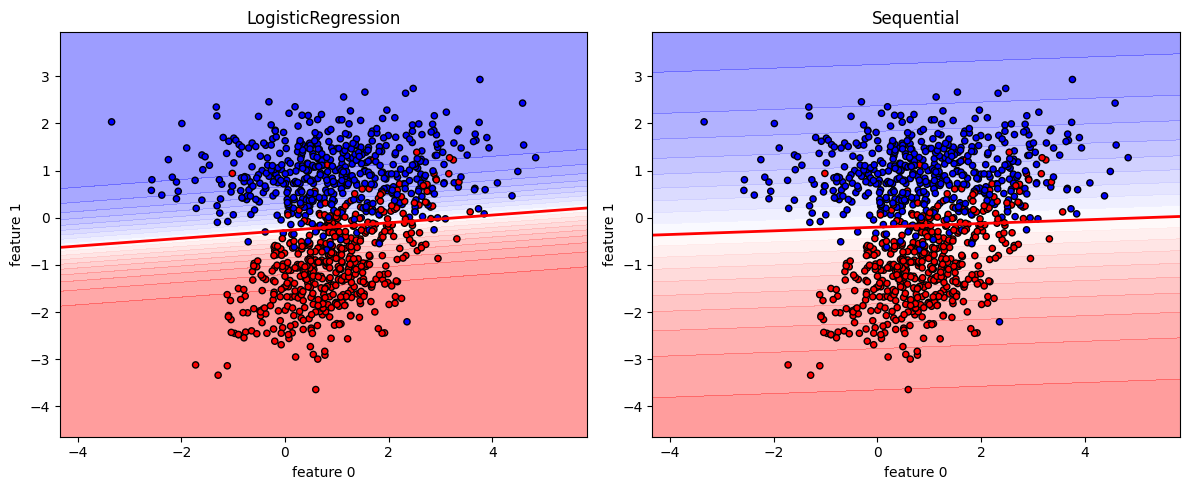

In [39]:
import matplotlib.pyplot as plt
import numpy as np

def plot_2d_boundary(model, X, y, feat_idx=(0, 1), title="", is_logits=True, ax=None):
    X = np.asarray(X); y = np.asarray(y)
    if ax is None:
        ax = plt.gca() # decide itself where (on which ax) to draw plot (if axes are not brought)
    xx, yy = np.meshgrid(
        np.linspace(X[:, feat_idx[0]].min()-1, X[:, feat_idx[0]].max()+1, 200),
        np.linspace(X[:, feat_idx[1]].min()-1, X[:, feat_idx[1]].max()+1, 200),
    )
    #base = X.mean(axis=0, keepdims=True)
    #grid = np.tile(base, (xx.size, 1))        # fill features that we dont visualize with mean
    grid = np.zeros((xx.size, X.shape[-1]))    # or with zeros for model.predict()
    grid[:, feat_idx[0]] = xx.ravel()
    grid[:, feat_idx[1]] = yy.ravel()

    out = model.predict(grid, verbose=0).ravel()
    probs = 1/(1+np.exp(-out)) if is_logits else out
    Z = probs.reshape(xx.shape)

    ax.contourf(xx, yy, Z, levels=20, cmap='bwr', alpha=0.4)
    ax.contour(xx, yy, Z, levels=[0.5], colors='red', linewidths=2) #when using levels=[...] (square brackets) in ax.contour, you specify the exact values of function Z, at which contour lines will be drawn.
    ax.scatter(X[:, feat_idx[0]], X[:, feat_idx[1]], c=y, cmap='bwr', edgecolor='k', s=20)
    ax.set_xlabel(f'feature {feat_idx[0]}'); ax.set_ylabel(f'feature {feat_idx[1]}')
    ax.set_title(title)

f, axes = plt.subplots(1, 2, figsize=(12, 5))
plot_2d_boundary(logreg,    x_train, y_train, ax=axes[0], title="LogisticRegression", is_logits=True)
plot_2d_boundary(seq_logreg, x_train, y_train, ax=axes[1], title="Sequential", is_logits=False)
plt.tight_layout(); plt.show()